In [5]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import laspy
import open3d as o3d
import geopandas as gpd

from shapely.geometry import box
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

In [6]:
# ============================================================
# CONFIG
# ============================================================

LAZ_INPUT_DIR = Path(
    "/path/to/authorized/raw_laz/"
)

OUTPUT_DIR = Path(
    "/path/to/authorized/processed_laz/"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SURVEY_INDEX_SHP = Path(
    "/path/to/project_storage/2026_Data/"
    "uxb_survey_index/uxb_survey_index.shp"
)

SHP_DIR = Path(
    "/path/to/project_storage/2026_Data/"
    "UXB_shapefiles_8April2024/"
)

TILE_SIZE = 100
TARGET_POINTS_PER_TILE = 70000

NORMAL_RADIUS = 1.0
POISSON_DEPTH = 7
DEM_RESOLUTION = 0.5

LOAD_WORKERS = 8

GROUND_CLASS = 2
STRUCTURE_CLASS = 6
PLAZUELA_CLASS = 27

NEIGHBOR_BUFFER = 10   # meters of neighboring tile context

GRID_SPACING = np.sqrt(
    (TILE_SIZE * TILE_SIZE)
    /
    TARGET_POINTS_PER_TILE
)

DEM_RESOLUTION = GRID_SPACING

print("Grid spacing:", GRID_SPACING)

USE_SHAPEFILES = True
USE_LOCAL_COORDS = False

Grid spacing: 0.3779644730092272


In [7]:
# ============================================================
# BASIC HELPERS
# ============================================================

def read_laz_xyz(path):
    las = laspy.read(path)
    xyz = np.column_stack((las.x, las.y, las.z))
    return xyz, las.header.parse_crs()


def tile_origin(path):
    x, y = path.stem.replace("100m_", "").split("_")[:2]
    return int(x), int(y)


def build_tile_index(files):
    rows = []

    for path in tqdm(files, desc="Indexing tiles"):
        x, y = tile_origin(path)

        rows.append({
            "path": path,
            "tile_x": x,
            "tile_y": y,
            "geometry": box(
                x,
                y,
                x + TILE_SIZE,
                y + TILE_SIZE
            )
        })

    return rows


def make_tile_lookup(tile_index):
    return {
        (r["tile_x"], r["tile_y"]): r["path"]
        for r in tile_index
    }

In [8]:
# ============================================================
# SELECT CENTER TILES INSIDE SURVEY INDEX
# ============================================================

def select_survey_tiles(tile_index, survey_path, crs):

    survey = gpd.read_file(survey_path)

    if survey.crs != crs:
        survey = survey.to_crs(crs)

    survey_geom = (
        survey.geometry.union_all()
        if hasattr(survey.geometry, "union_all")
        else survey.unary_union
    )

    selected = [
        r for r in tile_index
        if r["geometry"].intersects(survey_geom)
    ]

    print("All available tiles:", len(tile_index))
    print("Survey-index tiles:", len(selected))

    return selected

In [9]:
# ============================================================
# CENTER + 8 NEIGHBORS
# ============================================================

def get_neighbors(x, y, tile_lookup):

    offsets = [
        (-100, 100), (0, 100), (100, 100),
        (-100,   0), (0,   0), (100,   0),
        (-100,-100), (0,-100), (100,-100)
    ]

    return [
        tile_lookup[(x + dx, y + dy)]
        for dx, dy in offsets
        if (x + dx, y + dy) in tile_lookup
    ]


# ============================================================
# LOAD CENTER TILE + ONLY 25 m FROM TOUCHING NEIGHBORS
#
# Final merged extent around center:
#
#       center tile = 100 x 100 m
#       buffer      = 25 m on each side
#
# total context H 150 x 150 m
# ============================================================

def load_neighbors(
    paths,
    center_x,
    center_y
):

    # Desired buffered area around CENTER tile
    xmin = center_x - NEIGHBOR_BUFFER
    xmax = center_x + TILE_SIZE + NEIGHBOR_BUFFER

    ymin = center_y - NEIGHBOR_BUFFER
    ymax = center_y + TILE_SIZE + NEIGHBOR_BUFFER


    def load_and_crop(path):

        xyz, crs = read_laz_xyz(path)

        # Keep only points inside the 25 m buffered extent
        mask = (
            (xyz[:, 0] >= xmin)
            &
            (xyz[:, 0] < xmax)
            &
            (xyz[:, 1] >= ymin)
            &
            (xyz[:, 1] < ymax)
        )

        return xyz[mask], crs


    xyz_list = []
    common_crs = None


    with ThreadPoolExecutor(
        max_workers=LOAD_WORKERS
    ) as ex:

        futures = [
            ex.submit(
                load_and_crop,
                path
            )
            for path in paths
        ]


        for future in as_completed(
            futures
        ):

            xyz, crs = future.result()

            if len(xyz) > 0:
                xyz_list.append(xyz)

            if common_crs is None:
                common_crs = crs


    if not xyz_list:
        return None, common_crs


    merged_xyz = np.vstack(
        xyz_list
    )

    return merged_xyz, common_crs

In [10]:
# ============================================================
# LOAD CLASSIFICATION SHAPEFILES
# ============================================================

def load_classification_shapes(crs):

    structure_shp = list(
        SHP_DIR.glob("*Structure*.shp")
    )[0]

    plazuela_shp = list(
        SHP_DIR.glob("*Plazuela*.shp")
    )[0]

    structures = gpd.read_file(structure_shp)
    plazuelas = gpd.read_file(plazuela_shp)

    if structures.crs != crs:
        structures = structures.to_crs(crs)

    if plazuelas.crs != crs:
        plazuelas = plazuelas.to_crs(crs)

    return structures, plazuelas

In [11]:
def sample_mesh_grid(
    mesh,
    xmin,
    xmax,
    ymin,
    ymax,
    spacing
):

    # --------------------------------------------------------
    # Regular XY grid
    # --------------------------------------------------------

    xs = np.arange(
        xmin,
        xmax,
        spacing
    )

    ys = np.arange(
        ymin,
        ymax,
        spacing
    )

    xx, yy = np.meshgrid(
        xs,
        ys
    )

    xy = np.column_stack([
        xx.ravel(),
        yy.ravel()
    ])


    # --------------------------------------------------------
    # Convert legacy Open3D mesh to tensor mesh
    # --------------------------------------------------------

    tmesh = (
        o3d.t.geometry.TriangleMesh
        .from_legacy(mesh)
    )

    scene = (
        o3d.t.geometry.RaycastingScene()
    )

    scene.add_triangles(
        tmesh
    )


    # --------------------------------------------------------
    # Shoot rays downward from above mesh
    # --------------------------------------------------------

    z_top = (
        np.asarray(mesh.vertices)[:, 2].max()
        +
        10
    )

    origins = np.column_stack([

        xy[:, 0],

        xy[:, 1],

        np.full(
            len(xy),
            z_top
        )

    ])


    directions = np.tile(
        [0.0, 0.0, -1.0],
        (len(xy), 1)
    )


    rays = np.hstack([
        origins,
        directions
    ]).astype(
        np.float32
    )


    result = scene.cast_rays(
        o3d.core.Tensor(
            rays
        )
    )


    t_hit = (
        result["t_hit"]
        .numpy()
    )


    valid = np.isfinite(
        t_hit
    )


    z = (
        origins[valid, 2]
        -
        t_hit[valid]
    )


    sampled_xyz = np.column_stack([

        xy[valid, 0],

        xy[valid, 1],

        z

    ])


    return sampled_xyz

In [12]:
# ============================================================
# REMESH CENTER + 25 m NEIGHBOR CONTEXT
# ============================================================

def remesh_neighbors(xyz):

    '''print(
        "Points used for remeshing:",
        f"{len(xyz):,}"
    )'''

    # --------------------------------------------------------
    # CREATE POINT CLOUD
    # --------------------------------------------------------

    pcd = o3d.geometry.PointCloud()

    pcd.points = (
        o3d.utility.Vector3dVector(
            xyz
        )
    )

    pcd.remove_duplicated_points()
    pcd.remove_non_finite_points()


    # --------------------------------------------------------
    # NORMALS
    # --------------------------------------------------------

    pcd.estimate_normals(

        search_param=(
            o3d.geometry
            .KDTreeSearchParamHybrid(

                radius=NORMAL_RADIUS,

                max_nn=30

            )
        )

    )


    try:

        pcd.orient_normals_consistent_tangent_plane(
            30
        )

    except Exception:

        pass


    # --------------------------------------------------------
    # POISSON REMESH
    # --------------------------------------------------------

    mesh, _ = (

        o3d.geometry.TriangleMesh
        .create_from_point_cloud_poisson(

            pcd,

            depth=POISSON_DEPTH,

            scale=1.0,

            linear_fit=True

        )

    )


    del pcd

    gc.collect()


    mesh.remove_degenerate_triangles()
    mesh.remove_duplicated_triangles()
    mesh.remove_duplicated_vertices()
    mesh.remove_non_manifold_edges()


    # --------------------------------------------------------
    # CROP MESH TO ACTUAL BUFFERED INPUT AREA
    # --------------------------------------------------------

    mins = xyz.min(axis=0)

    maxs = xyz.max(axis=0)


    bbox = (

        o3d.geometry
        .AxisAlignedBoundingBox(

            min_bound=(

                mins[0],

                mins[1],

                mins[2] - 5

            ),

            max_bound=(

                maxs[0],

                maxs[1],

                maxs[2] + 5

            )

        )

    )


    mesh = mesh.crop(
        bbox
    )


    # --------------------------------------------------------
    # PRESERVE SAME APPROXIMATE POINT DENSITY
    #
    # Original:
    #
    # 100 x 100 = 10,000 m²
    # 70,000 points
    #
    # = 7 points / m²
    #
    # Buffered:
    #
    # 150 x 150 = 22,500 m²
    #
    # target H 157,500 points
    # --------------------------------------------------------

    sampled_xyz = sample_mesh_grid(
        mesh,
        xmin=mins[0],
        xmax=maxs[0],
        ymin=mins[1],
        ymax=maxs[1],
        spacing=GRID_SPACING
    )

    '''print(
        "Grid sampled points:",
        f"{len(sampled_xyz):,}"
    )'''

    del mesh
    gc.collect()

    return sampled_xyz

In [13]:
# ============================================================
# CLASSIFICATION
# ============================================================

def classify_points(xyz, structures, plazuelas, crs):

    labels = np.full(
        len(xyz),
        GROUND_CLASS,
        dtype=np.int32
    )

    bounds = box(
        xyz[:, 0].min(),
        xyz[:, 1].min(),
        xyz[:, 0].max(),
        xyz[:, 1].max()
    )

    pts = gpd.GeoDataFrame(
        {"idx": np.arange(len(xyz))},
        geometry=gpd.points_from_xy(
            xyz[:, 0],
            xyz[:, 1]
        ),
        crs=crs
    )

    for shp, cls in [
        (plazuelas, PLAZUELA_CLASS),
        (structures, STRUCTURE_CLASS)
    ]:

        local = shp[
            shp.intersects(bounds)
        ][["geometry"]]

        if len(local) == 0:
            continue

        joined = gpd.sjoin(
            pts,
            local,
            how="inner",
            predicate="within"
        )

        labels[
            joined["idx"].unique()
        ] = cls

    return labels

In [14]:
# ============================================================
# CLASSIFICATION
# ============================================================

def classify_points(xyz, structures, plazuelas, crs):

    labels = np.full(
        len(xyz),
        GROUND_CLASS,
        dtype=np.int32
    )

    bounds = box(
        xyz[:, 0].min(),
        xyz[:, 1].min(),
        xyz[:, 0].max(),
        xyz[:, 1].max()
    )

    pts = gpd.GeoDataFrame(
        {"idx": np.arange(len(xyz))},
        geometry=gpd.points_from_xy(
            xyz[:, 0],
            xyz[:, 1]
        ),
        crs=crs
    )

    for shp, cls in [
        (plazuelas, PLAZUELA_CLASS),
        (structures, STRUCTURE_CLASS)
    ]:

        local = shp[
            shp.intersects(bounds)
        ][["geometry"]]

        if len(local) == 0:
            continue

        joined = gpd.sjoin(
            pts,
            local,
            how="inner",
            predicate="within"
        )

        labels[
            joined["idx"].unique()
        ] = cls

    return labels

In [15]:
def create_dem(xyz):

    x = xyz[:, 0]
    y = xyz[:, 1]
    z = xyz[:, 2]

    xmin = x.min()
    xmax = x.max()

    ymin = y.min()
    ymax = y.max()

    xs = np.arange(
        xmin,
        xmax + GRID_SPACING / 2,
        GRID_SPACING
    )

    ys = np.arange(
        ymin,
        ymax + GRID_SPACING / 2,
        GRID_SPACING
    )

    w = len(xs)
    h = len(ys)

    dem = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    col = np.rint(
        (x - xmin)
        /
        GRID_SPACING
    ).astype(int)

    row = np.rint(
        (ymax - y)
        /
        GRID_SPACING
    ).astype(int)

    valid = (
        (row >= 0)
        &
        (row < h)
        &
        (col >= 0)
        &
        (col < w)
    )

    dem[
        row[valid],
        col[valid]
    ] = z[valid]

    return dem, xmin, ymax


def calculate_slope(dem):

    filled = dem.copy()
    filled[np.isnan(filled)] = np.nanmean(filled)

    a = filled[:-2, :-2]
    b = filled[:-2, 1:-1]
    c = filled[:-2, 2:]
    d = filled[1:-1, :-2]
    f = filled[1:-1, 2:]
    g = filled[2:, :-2]
    h = filled[2:, 1:-1]
    i = filled[2:, 2:]

    dx = (
        (c + 2*f + i)
        -
        (a + 2*d + g)
    ) / (8 * DEM_RESOLUTION)

    dy = (
        (g + 2*h + i)
        -
        (a + 2*b + c)
    ) / (8 * DEM_RESOLUTION)

    inner = np.degrees(
        np.arctan(
            np.sqrt(dx**2 + dy**2)
        )
    )

    slope = np.full(
        dem.shape,
        np.nan,
        dtype=np.float32
    )

    slope[1:-1, 1:-1] = inner
    slope[np.isnan(slope)] = np.nanmean(slope)

    return slope


def sample_slope(xyz, slope, xmin, ymax):

    col = (
        (xyz[:, 0] - xmin)
        /
        DEM_RESOLUTION
    ).astype(int)

    row = (
        (ymax - xyz[:, 1])
        /
        DEM_RESOLUTION
    ).astype(int)

    row = np.clip(
        row,
        0,
        slope.shape[0] - 1
    )

    col = np.clip(
        col,
        0,
        slope.shape[1] - 1
    )

    return slope[row, col]

In [16]:
# ============================================================
# SAVE FINAL POINT CLOUD AS COMPRESSED LAZ
#
# Stores:
# x, y, z
# classification
# planar_slope_degrees as extra dimension
# ============================================================

def save_laz_with_slope(
    output_path,
    xyz,
    slopes,
    labels,
    crs=None
):
    # Temporary file while writing
    temp_path = output_path.with_name(
        output_path.stem + "_TEMP.laz"
    )

    header = laspy.LasHeader(
        point_format=3,
        version="1.2"
    )

    header.scales = [
        0.001,
        0.001,
        0.001
    ]

    header.offsets = [
        float(xyz[:, 0].min()),
        float(xyz[:, 1].min()),
        float(xyz[:, 2].min())
    ]

    if crs is not None:
        header.add_crs(crs)

    las = laspy.LasData(header)

    las.x = xyz[:, 0]
    las.y = xyz[:, 1]
    las.z = xyz[:, 2]

    las.classification = labels.astype(
        np.uint8
    )

    las.add_extra_dim(
        laspy.ExtraBytesParams(
            name="slope",
            type=np.float32,
            description="Planar slope in degrees"
        )
    )

    las.slope = slopes.astype(
        np.float32
    )

    # Write incomplete output as TEMP first
    las.write(temp_path)

    # Rename only after successful completion
    temp_path.replace(output_path)

In [17]:
# ============================================================
# PROCESS ONE CENTER TILE
# ============================================================

def process_tile(
    center,
    tile_lookup,
    structures,
    plazuelas,
    crs
):

    path = center["path"]
    x = center["tile_x"]
    y = center["tile_y"]

    neighbor_paths = get_neighbors(
        x,
        y,
        tile_lookup
    )

    merged_xyz, _ = load_neighbors(
        neighbor_paths,
        x,
        y
    )

    sampled_xyz = remesh_neighbors(
        merged_xyz
    )

    del merged_xyz
    gc.collect()

    if USE_SHAPEFILES:

        labels = classify_points(
            sampled_xyz,
            structures,
            plazuelas,
            crs
        )

    else:

        labels = np.full(
            len(sampled_xyz),
            GROUND_CLASS,
            dtype=np.int32
        )

    # ============================================================
    # PLANAR SLOPE USING ALL POINTS
    #
    # Includes:
    # - Ground
    # - Structure
    # - Plazuela
    # ============================================================

    dem, xmin, ymax = create_dem(
        sampled_xyz
    )

    slope_raster = calculate_slope(
        dem
    )

    # Assign planar slope back to EVERY point
    slopes = sample_slope(
        sampled_xyz,
        slope_raster,
        xmin,
        ymax
    )

    # --------------------------------------------------------
    # Crop only center 100 m tile
    # --------------------------------------------------------

    mask = (
        (sampled_xyz[:, 0] >= x)
        &
        (sampled_xyz[:, 0] < x + TILE_SIZE)
        &
        (sampled_xyz[:, 1] >= y)
        &
        (sampled_xyz[:, 1] < y + TILE_SIZE)
    )

    xyz = sampled_xyz[mask].copy()
    tile_labels = labels[mask]
    tile_slopes = slopes[mask]

    if USE_LOCAL_COORDS:
        xyz[:, 0] -= x
        xyz[:, 1] -= y

    # ============================================================
    # SAVE FINAL CENTER TILE AS LAZ
    # ============================================================

    out_name = (
        path.stem
        +
        "_remesh_grid_slope.laz"
    )

    save_laz_with_slope(
        OUTPUT_DIR / out_name,
        xyz,
        tile_slopes,
        tile_labels,
        crs=crs
    )

    del sampled_xyz, labels, slopes
    del dem, slope_raster
    gc.collect()

    return {
        "file": path.name,
        "neighbors_loaded": len(neighbor_paths),
        "final_points": len(xyz)
    }

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d import Axes3D

In [19]:
# ============================================================
# VISUALIZATION HELPERS
# ============================================================

def plot_points_3d(xyz, title, max_points=100000):
    """Plot a random subset for visualization only."""

    if len(xyz) > max_points:
        idx = np.random.choice(
            len(xyz),
            max_points,
            replace=False
        )
        p = xyz[idx]
    else:
        p = xyz

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    ax.scatter(
        p[:, 0],
        p[:, 1],
        p[:, 2],
        s=0.4
    )

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    plt.tight_layout()
    plt.show()


def plot_topdown(xyz, title, labels=None, max_points=150000):

    if len(xyz) > max_points:
        idx = np.random.choice(
            len(xyz),
            max_points,
            replace=False
        )
        p = xyz[idx]

        if labels is not None:
            labels_plot = labels[idx]
    else:
        p = xyz

        if labels is not None:
            labels_plot = labels

    plt.figure(figsize=(8, 8))

    if labels is None:

        plt.scatter(
            p[:, 0],
            p[:, 1],
            s=0.5
        )

    else:

        for cls, name in [
            (GROUND_CLASS, "Ground"),
            (PLAZUELA_CLASS, "Plazuela"),
            (STRUCTURE_CLASS, "Structure")
        ]:

            m = labels_plot == cls

            if np.any(m):
                plt.scatter(
                    p[m, 0],
                    p[m, 1],
                    s=0.6,
                    label=name
                )

        plt.legend()

    plt.axis("equal")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)

    plt.tight_layout()
    plt.show()

In [20]:
# ============================================================
# PROCESS + VISUALIZE FIRST TILE
# ============================================================

def visualize_and_process_first_tile(
    center,
    tile_lookup,
    structures,
    plazuelas,
    crs
):

    path = center["path"]
    x = center["tile_x"]
    y = center["tile_y"]

    print("=" * 70)
    print("FIRST TILE VISUALIZATION")
    print("Center:", path.name)
    print("Origin:", x, y)
    print("=" * 70)


    # ========================================================
    # STEP 1  CENTER TILE + 25 m NEIGHBOR CONTEXT
    # ========================================================

    neighbor_paths = get_neighbors(
        x,
        y,
        tile_lookup
    )

    print(
        f"\nSTEP 1: Found {len(neighbor_paths)} "
        "available tiles including center"
    )

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    # Show available 100 m source tiles
    for neighbor_path in neighbor_paths:

        nx, ny = tile_origin(
            neighbor_path
        )

        is_center = (
            nx == x
            and
            ny == y
        )

        rect = Rectangle(
            (nx, ny),
            TILE_SIZE,
            TILE_SIZE,
            fill=is_center,
            alpha=0.20 if is_center else 1,
            linewidth=2 if is_center else 1
        )

        ax.add_patch(rect)

    # Center tile boundary
    ax.add_patch(
        Rectangle(
            (x, y),
            TILE_SIZE,
            TILE_SIZE,
            fill=False,
            linewidth=3,
            label="Center 100 m tile"
        )
    )

    # Actual 25 m buffered region used for processing
    ax.add_patch(
        Rectangle(
            (
                x - NEIGHBOR_BUFFER,
                y - NEIGHBOR_BUFFER
            ),
            TILE_SIZE + 2 * NEIGHBOR_BUFFER,
            TILE_SIZE + 2 * NEIGHBOR_BUFFER,
            fill=False,
            linestyle="--",
            linewidth=3,
            label="10 m processing buffer"
        )
    )

    ax.set_xlim(
        x - TILE_SIZE - 10,
        x + 2 * TILE_SIZE + 10
    )

    ax.set_ylim(
        y - TILE_SIZE - 10,
        y + 2 * TILE_SIZE + 10
    )

    ax.set_aspect("equal")

    ax.set_title(
        "Step 1 - Center Tile + 25 m Neighbor Context"
    )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.legend()

    plt.tight_layout()
    plt.show()


    # ========================================================
    # STEP 2  LOAD CENTER + ONLY 25 m FROM NEIGHBORS
    # ========================================================

    merged_xyz, _ = load_neighbors(
        neighbor_paths,
        x,
        y
    )

    if merged_xyz is None or len(merged_xyz) == 0:
        raise ValueError(
            "No points loaded for center + neighbor buffer."
        )

    print(
        "\nSTEP 2: Points used after 25 m neighbor cropping:",
        f"{len(merged_xyz):,}"
    )

    plot_points_3d(
        merged_xyz,
        "Step 2 - Center Tile + 25 m Neighbor Points"
    )


    # ========================================================
    # STEP 3  POISSON REMESH
    # ========================================================

    print(
        "\nSTEP 3: Estimating normals and creating Poisson mesh..."
    )

    pcd = o3d.geometry.PointCloud()

    pcd.points = (
        o3d.utility.Vector3dVector(
            merged_xyz
        )
    )

    pcd.remove_duplicated_points()
    pcd.remove_non_finite_points()

    pcd.estimate_normals(
        search_param=(
            o3d.geometry.KDTreeSearchParamHybrid(
                radius=NORMAL_RADIUS,
                max_nn=30
            )
        )
    )

    try:

        pcd.orient_normals_consistent_tangent_plane(
            30
        )

    except Exception:

        pass


    mesh, _ = (
        o3d.geometry.TriangleMesh
        .create_from_point_cloud_poisson(
            pcd,
            depth=POISSON_DEPTH,
            scale=1.0,
            linear_fit=True
        )
    )

    mesh.remove_degenerate_triangles()
    mesh.remove_duplicated_triangles()
    mesh.remove_duplicated_vertices()
    mesh.remove_non_manifold_edges()


    # Crop reconstructed mesh to actual point extent
    mins = merged_xyz.min(
        axis=0
    )

    maxs = merged_xyz.max(
        axis=0
    )

    bbox = (
        o3d.geometry.AxisAlignedBoundingBox(

            min_bound=(
                mins[0],
                mins[1],
                mins[2] - 5
            ),

            max_bound=(
                maxs[0],
                maxs[1],
                maxs[2] + 5
            )
        )
    )

    mesh = mesh.crop(
        bbox
    )

    print(
        "Mesh vertices:",
        f"{len(mesh.vertices):,}"
    )

    print(
        "Mesh triangles:",
        f"{len(mesh.triangles):,}"
    )


    mesh_vertices = np.asarray(
        mesh.vertices
    )

    plot_points_3d(
        mesh_vertices,
        "Step 3 - Poisson Reconstructed Surface"
    )


    # ========================================================
    # STEP 4  RESAMPLE BUFFERED MESH
    #
    # Original target density:
    #
    # 70,000 points / 10,000 m²
    # = 7 points/m²
    #
    # 25 m buffer gives approximately:
    #
    # 150 × 150 = 22,500 m²
    # target H 157,500 points
    # ========================================================

    point_density = (
        TARGET_POINTS_PER_TILE
        /
        (TILE_SIZE * TILE_SIZE)
    )

    buffered_size = (
        TILE_SIZE
        +
        2 * NEIGHBOR_BUFFER
    )
    
    sampled_xyz = sample_mesh_grid(
        mesh,
        xmin=mins[0],
        xmax=maxs[0],
        ymin=mins[1],
        ymax=maxs[1],
        spacing=GRID_SPACING
    )

    print(
        "\nSTEP 4: Regular grid sampled points:",
        f"{len(sampled_xyz):,}"
    )

    print(
        "Grid spacing:",
        f"{GRID_SPACING:.4f} m"
    )

    plot_points_3d(
        sampled_xyz,
        "Step 4 - Regular XY Grid Sampled Surface"
    )

    del pcd
    del mesh

    del merged_xyz

    gc.collect()


    # ========================================================
    # STEP 5  CLASSIFICATION
    # ========================================================

    if USE_SHAPEFILES:

        labels = classify_points(
            sampled_xyz,
            structures,
            plazuelas,
            crs
        )

    else:

        labels = np.full(
            len(sampled_xyz),
            GROUND_CLASS,
            dtype=np.int32
        )


    print(
        "\nSTEP 5: Classification"
    )

    unique, counts = np.unique(
        labels,
        return_counts=True
    )

    class_counts = dict(
        zip(
            unique.tolist(),
            counts.tolist()
        )
    )

    print(
        "Class counts:",
        class_counts
    )


    plot_topdown(
        sampled_xyz,
        "Step 5 - Classified Resampled Points",
        labels=labels
    )


    # ========================================================
    # STEP 6  CREATE ELEVATION SURFACE USING ALL POINTS
    #
    # IMPORTANT:
    #
    # We DO NOT remove Structure or Plazuela points.
    #
    # Ground     = included
    # Structure  = included
    # Plazuela   = included
    #
    # create_dem() should use highest Z per XY raster cell.
    # ========================================================

    print(
        "\nSTEP 6: Creating elevation surface from ALL",
        f"{len(sampled_xyz):,}",
        "resampled points"
    )

    dem, xmin, ymax = create_dem(
        sampled_xyz
    )


    plt.figure(
        figsize=(9, 7)
    )

    plt.imshow(
        dem,
        origin="upper"
    )

    plt.colorbar(
        label="Elevation"
    )

    plt.title(
        "Step 6 - Elevation Surface from All Points"
    )

    plt.xlabel(
        "Raster column"
    )

    plt.ylabel(
        "Raster row"
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # STEP 7  PLANAR SLOPE
    #
    # Planar slope is calculated from the elevation raster
    # using the existing 3x3 dz/dx and dz/dy method.
    #
    # Then slope is sampled back to EVERY point.
    # ========================================================

    print(
        "\nSTEP 7: Calculating planar slope..."
    )

    slope_raster = calculate_slope(
        dem
    )


    plt.figure(
        figsize=(9, 7)
    )

    plt.imshow(
        slope_raster,
        origin="upper"
    )

    plt.colorbar(
        label="Planar slope (degrees)"
    )

    plt.title(
        "Step 7A - Planar Slope of Buffered Surface"
    )

    plt.xlabel(
        "Raster column"
    )

    plt.ylabel(
        "Raster row"
    )

    plt.tight_layout()
    plt.show()


    # Assign planar slope to ALL sampled points
    slopes = sample_slope(
        sampled_xyz,
        slope_raster,
        xmin,
        ymax
    )

    print(
        "Slope assigned to:",
        f"{len(slopes):,}",
        "points"
    )

    print(
        f"Slope range: "
        f"{np.nanmin(slopes):.2f}° - "
        f"{np.nanmax(slopes):.2f}°"
    )


    # ========================================================
    # STEP 7B  VISUALIZE POINTS BY PLANAR SLOPE
    # ========================================================

    n_viz = min(
        len(sampled_xyz),
        150000
    )

    viz_idx = np.random.choice(
        len(sampled_xyz),
        n_viz,
        replace=False
    )

    plt.figure(
        figsize=(9, 8)
    )

    sc = plt.scatter(
        sampled_xyz[viz_idx, 0],
        sampled_xyz[viz_idx, 1],
        c=slopes[viz_idx],
        s=0.5
    )

    plt.colorbar(
        sc,
        label="Planar slope (degrees)"
    )

    plt.axis(
        "equal"
    )

    plt.title(
        "Step 7B - Planar Slope Assigned to All Points"
    )

    plt.xlabel(
        "X"
    )

    plt.ylabel(
        "Y"
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # STEP 8  CROP ONLY CENTER 100 m TILE
    # ========================================================

    mask = (
        (sampled_xyz[:, 0] >= x)
        &
        (sampled_xyz[:, 0] < x + TILE_SIZE)
        &
        (sampled_xyz[:, 1] >= y)
        &
        (sampled_xyz[:, 1] < y + TILE_SIZE)
    )


    center_xyz = sampled_xyz[
        mask
    ].copy()

    center_labels = labels[
        mask
    ]

    center_slopes = slopes[
        mask
    ]


    print(
        "\nSTEP 8: Final center tile points:",
        f"{len(center_xyz):,}"
    )


    # --------------------------------------------------------
    # Full buffered region + center tile rectangle
    # --------------------------------------------------------

    n_viz = min(
        len(sampled_xyz),
        150000
    )

    viz_idx = np.random.choice(
        len(sampled_xyz),
        n_viz,
        replace=False
    )

    plt.figure(
        figsize=(8, 8)
    )

    plt.scatter(
        sampled_xyz[viz_idx, 0],
        sampled_xyz[viz_idx, 1],
        s=0.3
    )

    ax = plt.gca()

    ax.add_patch(
        Rectangle(
            (x, y),
            TILE_SIZE,
            TILE_SIZE,
            fill=False,
            linewidth=3
        )
    )

    plt.axis(
        "equal"
    )

    plt.title(
        "Step 8A - Final Center 100 m Crop"
    )

    plt.xlabel(
        "X"
    )

    plt.ylabel(
        "Y"
    )

    plt.tight_layout()
    plt.show()


    # --------------------------------------------------------
    # Final center tile by class
    # --------------------------------------------------------

    plot_topdown(
        center_xyz,
        "Step 8B - Final Center Tile by Class",
        labels=center_labels
    )


    # --------------------------------------------------------
    # Final center tile by planar slope
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 8)
    )

    sc = plt.scatter(
        center_xyz[:, 0],
        center_xyz[:, 1],
        c=center_slopes,
        s=0.7
    )

    plt.colorbar(
        sc,
        label="Planar slope (degrees)"
    )

    plt.axis(
        "equal"
    )

    plt.title(
        "Step 8C - Final Center Tile Planar Slope"
    )

    plt.xlabel(
        "X"
    )

    plt.ylabel(
        "Y"
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # STEP 9  SAVE FINAL CENTER TILE AS COMPRESSED LAZ
    # ========================================================

    output_xyz = center_xyz.copy()

    if USE_LOCAL_COORDS:

        output_xyz[:, 0] -= x
        output_xyz[:, 1] -= y


    out_name = (
        path.stem
        +
        "_remesh_grid_slope.laz"
    )


    save_laz_with_slope(
        OUTPUT_DIR / out_name,
        output_xyz,
        center_slopes,
        center_labels,
        crs=crs
    )


    print(
        "\nSTEP 9: Saved:"
    )

    print(
        OUTPUT_DIR / out_name
    )


    # ========================================================
    # CLEANUP
    # ========================================================

    del sampled_xyz
    del labels
    del slopes
    del dem
    del slope_raster

    gc.collect()


    return {

        "file":
            path.name,

        "neighbors_loaded":
            len(neighbor_paths),

        "final_points":
            len(center_xyz)

    }

In [21]:
def save_laz_with_slope(
    output_path,
    xyz,
    slopes,
    labels,
    crs=None
):
    header = laspy.LasHeader(
        point_format=3,
        version="1.2"
    )

    header.scales = [
        0.001,
        0.001,
        0.001
    ]

    header.offsets = [
        xyz[:, 0].min(),
        xyz[:, 1].min(),
        xyz[:, 2].min()
    ]

    if crs is not None:
        header.add_crs(crs)

    las = laspy.LasData(header)

    las.x = xyz[:, 0]
    las.y = xyz[:, 1]
    las.z = xyz[:, 2]

    las.classification = labels.astype(
        np.uint8
    )

    las.add_extra_dim(
        laspy.ExtraBytesParams(
            name="slope",
            type=np.float32,
            description="Planar slope in degrees"
        )
    )

    las.slope = slopes.astype(
        np.float32
    )

    las.write(
        output_path
    )

In [19]:
# ============================================================
# MAIN - RESUME SAFE
# ============================================================

laz_files = sorted(
    LAZ_INPUT_DIR.glob("100m_*.laz")
)

if not laz_files:
    raise FileNotFoundError(
        "No LAZ files found."
    )


# ============================================================
# GET CRS + BUILD INDEX
# ============================================================

_, crs = read_laz_xyz(
    laz_files[0]
)

tile_index = build_tile_index(
    laz_files
)

tile_lookup = make_tile_lookup(
    tile_index
)

selected_tiles = select_survey_tiles(
    tile_index,
    SURVEY_INDEX_SHP,
    crs
)


# ============================================================
# LOAD CLASSIFICATION SHAPEFILES
# ============================================================

if USE_SHAPEFILES:

    structures, plazuelas = (
        load_classification_shapes(
            crs
        )
    )

else:

    structures = None
    plazuelas = None


# ============================================================
# REMOVE INCOMPLETE FILES FROM PREVIOUS CRASH
# ============================================================

temp_files = list(
    OUTPUT_DIR.glob("*_TEMP.laz")
)

for temp_file in temp_files:

    try:
        temp_file.unlink()

    except Exception as e:

        print(
            "Could not remove:",
            temp_file,
            e
        )


if temp_files:

    print(
        "Removed incomplete TEMP files:",
        len(temp_files)
    )


# ============================================================
# FIND TILES ALREADY COMPLETED
# ============================================================

remaining_tiles = []
completed_tiles = []

for tile in selected_tiles:

    expected_output = (
        OUTPUT_DIR
        /
        (
            tile["path"].stem
            +
            "_remesh_grid_slope.laz"
        )
    )

    if expected_output.exists():

        completed_tiles.append(
            tile
        )

    else:

        remaining_tiles.append(
            tile
        )


print()
print(
    "Total survey tiles:",
    len(selected_tiles)
)

print(
    "Already completed:",
    len(completed_tiles)
)

print(
    "Remaining:",
    len(remaining_tiles)
)


# ============================================================
# PROCESS ONLY UNFINISHED TILES
# ============================================================

records = []
failed = []


progress = tqdm(
    remaining_tiles,
    total=len(remaining_tiles),
    desc="Processing remaining tiles",
    unit="tile",
    dynamic_ncols=True,
    leave=True
)


for tile in progress:

    progress.set_postfix_str(

        f"{tile['path'].stem} | "
        f"Done: "
        f"{len(completed_tiles) + len(records)}"
        f"/{len(selected_tiles)} | "
        f"Failed: {len(failed)}"

    )


    try:

        result = process_tile(

            tile,

            tile_lookup,

            structures,

            plazuelas,

            crs

        )

        records.append(
            result
        )


    except Exception as e:

        failed.append({

            "file":
                tile["path"].name,

            "error":
                str(e)

        })

        tqdm.write(

            f'FAILED: '
            f'{tile["path"].name}: '
            f'{e}'

        )


    # --------------------------------------------------------
    # Save summaries after every tile
    # --------------------------------------------------------

    if records:

        pd.DataFrame(
            records
        ).to_csv(

            OUTPUT_DIR
            /
            "processing_summary_current_run.csv",

            index=False

        )


    if failed:

        pd.DataFrame(
            failed
        ).to_csv(

            OUTPUT_DIR
            /
            "failed_tiles.csv",

            index=False

        )


    gc.collect()


# ============================================================
# FINISHED
# ============================================================

print("\nDone")

print(
    "Total survey tiles:",
    len(selected_tiles)
)

print(
    "Previously completed:",
    len(completed_tiles)
)

print(
    "Processed this run:",
    len(records)
)

print(
    "Failed this run:",
    len(failed)
)

print(
    "Total completed now:",
    len(completed_tiles)
    +
    len(records)
)

Indexing tiles: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15002/15002 [00:00<00:00, 46154.07it/s]


All available tiles: 15002
Survey-index tiles: 1071

Total survey tiles: 1071
Already completed: 380
Remaining: 691


Processing remaining tiles:   5%|████▍                                                                               | 37/691 [02:36<56:27,  5.18s/tile, tile_redacted_0001 | Done: 417/1071 | Failed: 0][WARNING] /root/Open3D/build/poisson/src/ext_poisson/PoissonRecon/Src/FEMTree.IsoSurface.specialized.inl (Line 1858)
          Extract
          bad average roots: 3
Processing remaining tiles:  99%|█████████████████████████████████████████████████████████████████████████████████▌| 687/691 [40:42<00:22,  5.62s/tile, tile_redacted_0002 | Done: 1067/1071 | Failed: 0][WARNING] /root/Open3D/build/poisson/src/ext_poisson/PoissonRecon/Src/FEMTree.Evaluation.inl (Line 155)
          _getValues
          getValue assumes leaf node
[WARNING] /root/Open3D/build/poisson/src/ext_poisson/PoissonRecon/Src/FEMTree.Evaluation.inl (Line 155)
          _getValues
          getValue assumes leaf node
[WARNING] /root/Open3D/build/poisson/src/ext_poisson/PoissonRecon/Src/FEMTree.Evaluation.inl (Line 155)
    


Done
Total survey tiles: 1071
Previously completed: 380
Processed this run: 691
Failed this run: 0
Total completed now: 1071


In [1]:
from pathlib import Path
import shutil
import laspy
import numpy as np
from tqdm import tqdm

# ============================================================
# PATHS
# ============================================================

INPUT_DIR = Path(
    "/path/to/authorized/processed_laz/"
)

OUTPUT_DIR = Path(
    "/path/to/authorized/training_laz/"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CLASSES
# ============================================================

GROUND_CLASS = 2
STRUCTURE_CLASS = 6
PLAZUELA_CLASS = 27


# ============================================================
# FIND LAZ FILES
# ============================================================

laz_files = sorted(
    INPUT_DIR.glob("*.laz")
)

print("Total LAZ files found:", len(laz_files))


# ============================================================
# COUNTERS
# ============================================================

copied = 0
ground_only = 0
failed = []

ground_points = 0
structure_points = 0
plazuela_points = 0


# ============================================================
# FILTER + COPY + COUNT CLASSES
# ============================================================

for laz_path in tqdm(
    laz_files,
    desc="Filtering training tiles",
    unit="tile",
    dynamic_ncols=True
):

    try:

        las = laspy.read(
            laz_path
        )

        classes = np.asarray(
            las.classification
        )

        # ----------------------------------------------------
        # Count classes in this tile
        # ----------------------------------------------------

        n_ground = np.count_nonzero(
            classes == GROUND_CLASS
        )

        n_structure = np.count_nonzero(
            classes == STRUCTURE_CLASS
        )

        n_plazuela = np.count_nonzero(
            classes == PLAZUELA_CLASS
        )


        # ----------------------------------------------------
        # Keep tile if Structure OR Plazuela exists
        # ----------------------------------------------------

        keep = (
            n_structure > 0
            or
            n_plazuela > 0
        )


        if keep:

            output_path = (
                OUTPUT_DIR
                /
                laz_path.name
            )

            # Avoid unnecessary re-copying
            if not output_path.exists():

                shutil.copy2(
                    laz_path,
                    output_path
                )

            copied += 1

            # Only count points from FILTERED dataset
            ground_points += n_ground
            structure_points += n_structure
            plazuela_points += n_plazuela

        else:

            ground_only += 1


    except Exception as e:

        failed.append(
            (
                laz_path.name,
                str(e)
            )
        )


# ============================================================
# CLASS DISTRIBUTION
# ============================================================

total_classified_points = (
    ground_points
    +
    structure_points
    +
    plazuela_points
)


if total_classified_points > 0:

    ground_pct = (
        ground_points
        /
        total_classified_points
        *
        100
    )

    structure_pct = (
        structure_points
        /
        total_classified_points
        *
        100
    )

    plazuela_pct = (
        plazuela_points
        /
        total_classified_points
        *
        100
    )

else:

    ground_pct = 0
    structure_pct = 0
    plazuela_pct = 0


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FILTERING SUMMARY")
print("=" * 60)

print(
    "Total input LAZ files:",
    len(laz_files)
)

print(
    "Tiles copied:",
    copied
)

print(
    "Ground-only tiles skipped:",
    ground_only
)

print(
    "Failed:",
    len(failed)
)


print("\n" + "=" * 60)
print("FILTERED DATASET POINT DISTRIBUTION")
print("=" * 60)

print(
    f"Ground     (class {GROUND_CLASS:2d}): "
    f"{ground_points:,} "
    f"({ground_pct:.2f}%)"
)

print(
    f"Structure  (class {STRUCTURE_CLASS:2d}): "
    f"{structure_points:,} "
    f"({structure_pct:.2f}%)"
)

print(
    f"Plazuela   (class {PLAZUELA_CLASS:2d}): "
    f"{plazuela_points:,} "
    f"({plazuela_pct:.2f}%)"
)

print("-" * 60)

print(
    f"Total points: "
    f"{total_classified_points:,}"
)


print(
    "\nFiltered data saved to:"
)

print(
    OUTPUT_DIR
)


# ============================================================
# FAILED FILES
# ============================================================

if failed:

    print("\nFailed files:")

    for filename, error in failed[:20]:

        print(
            filename,
            "->",
            error
        )

Total LAZ files found: 1071


Filtering training tiles: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1071/1071 [00:55<00:00, 19.33tile/s]


FILTERING SUMMARY
Total input LAZ files: 1071
Tiles copied: 530
Ground-only tiles skipped: 541
Failed: 0

FILTERED DATASET POINT DISTRIBUTION
Ground     (class  2): 34,721,541 (93.50%)
Structure  (class  6): 369,557 (1.00%)
Plazuela   (class 27): 2,044,455 (5.51%)
------------------------------------------------------------
Total points: 37,135,553

Filtered data saved to:
/path/to/project_storage/2026_Data/training_data_filtered


Selected tile:
tile_redacted_0004.laz


/tmp/ipykernel_1570866/512950196.py:359: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.04, 0.02, 0.98, 0.97])


Saved figure to:
/path/to/authorized/training_laz/visualization_4views.png


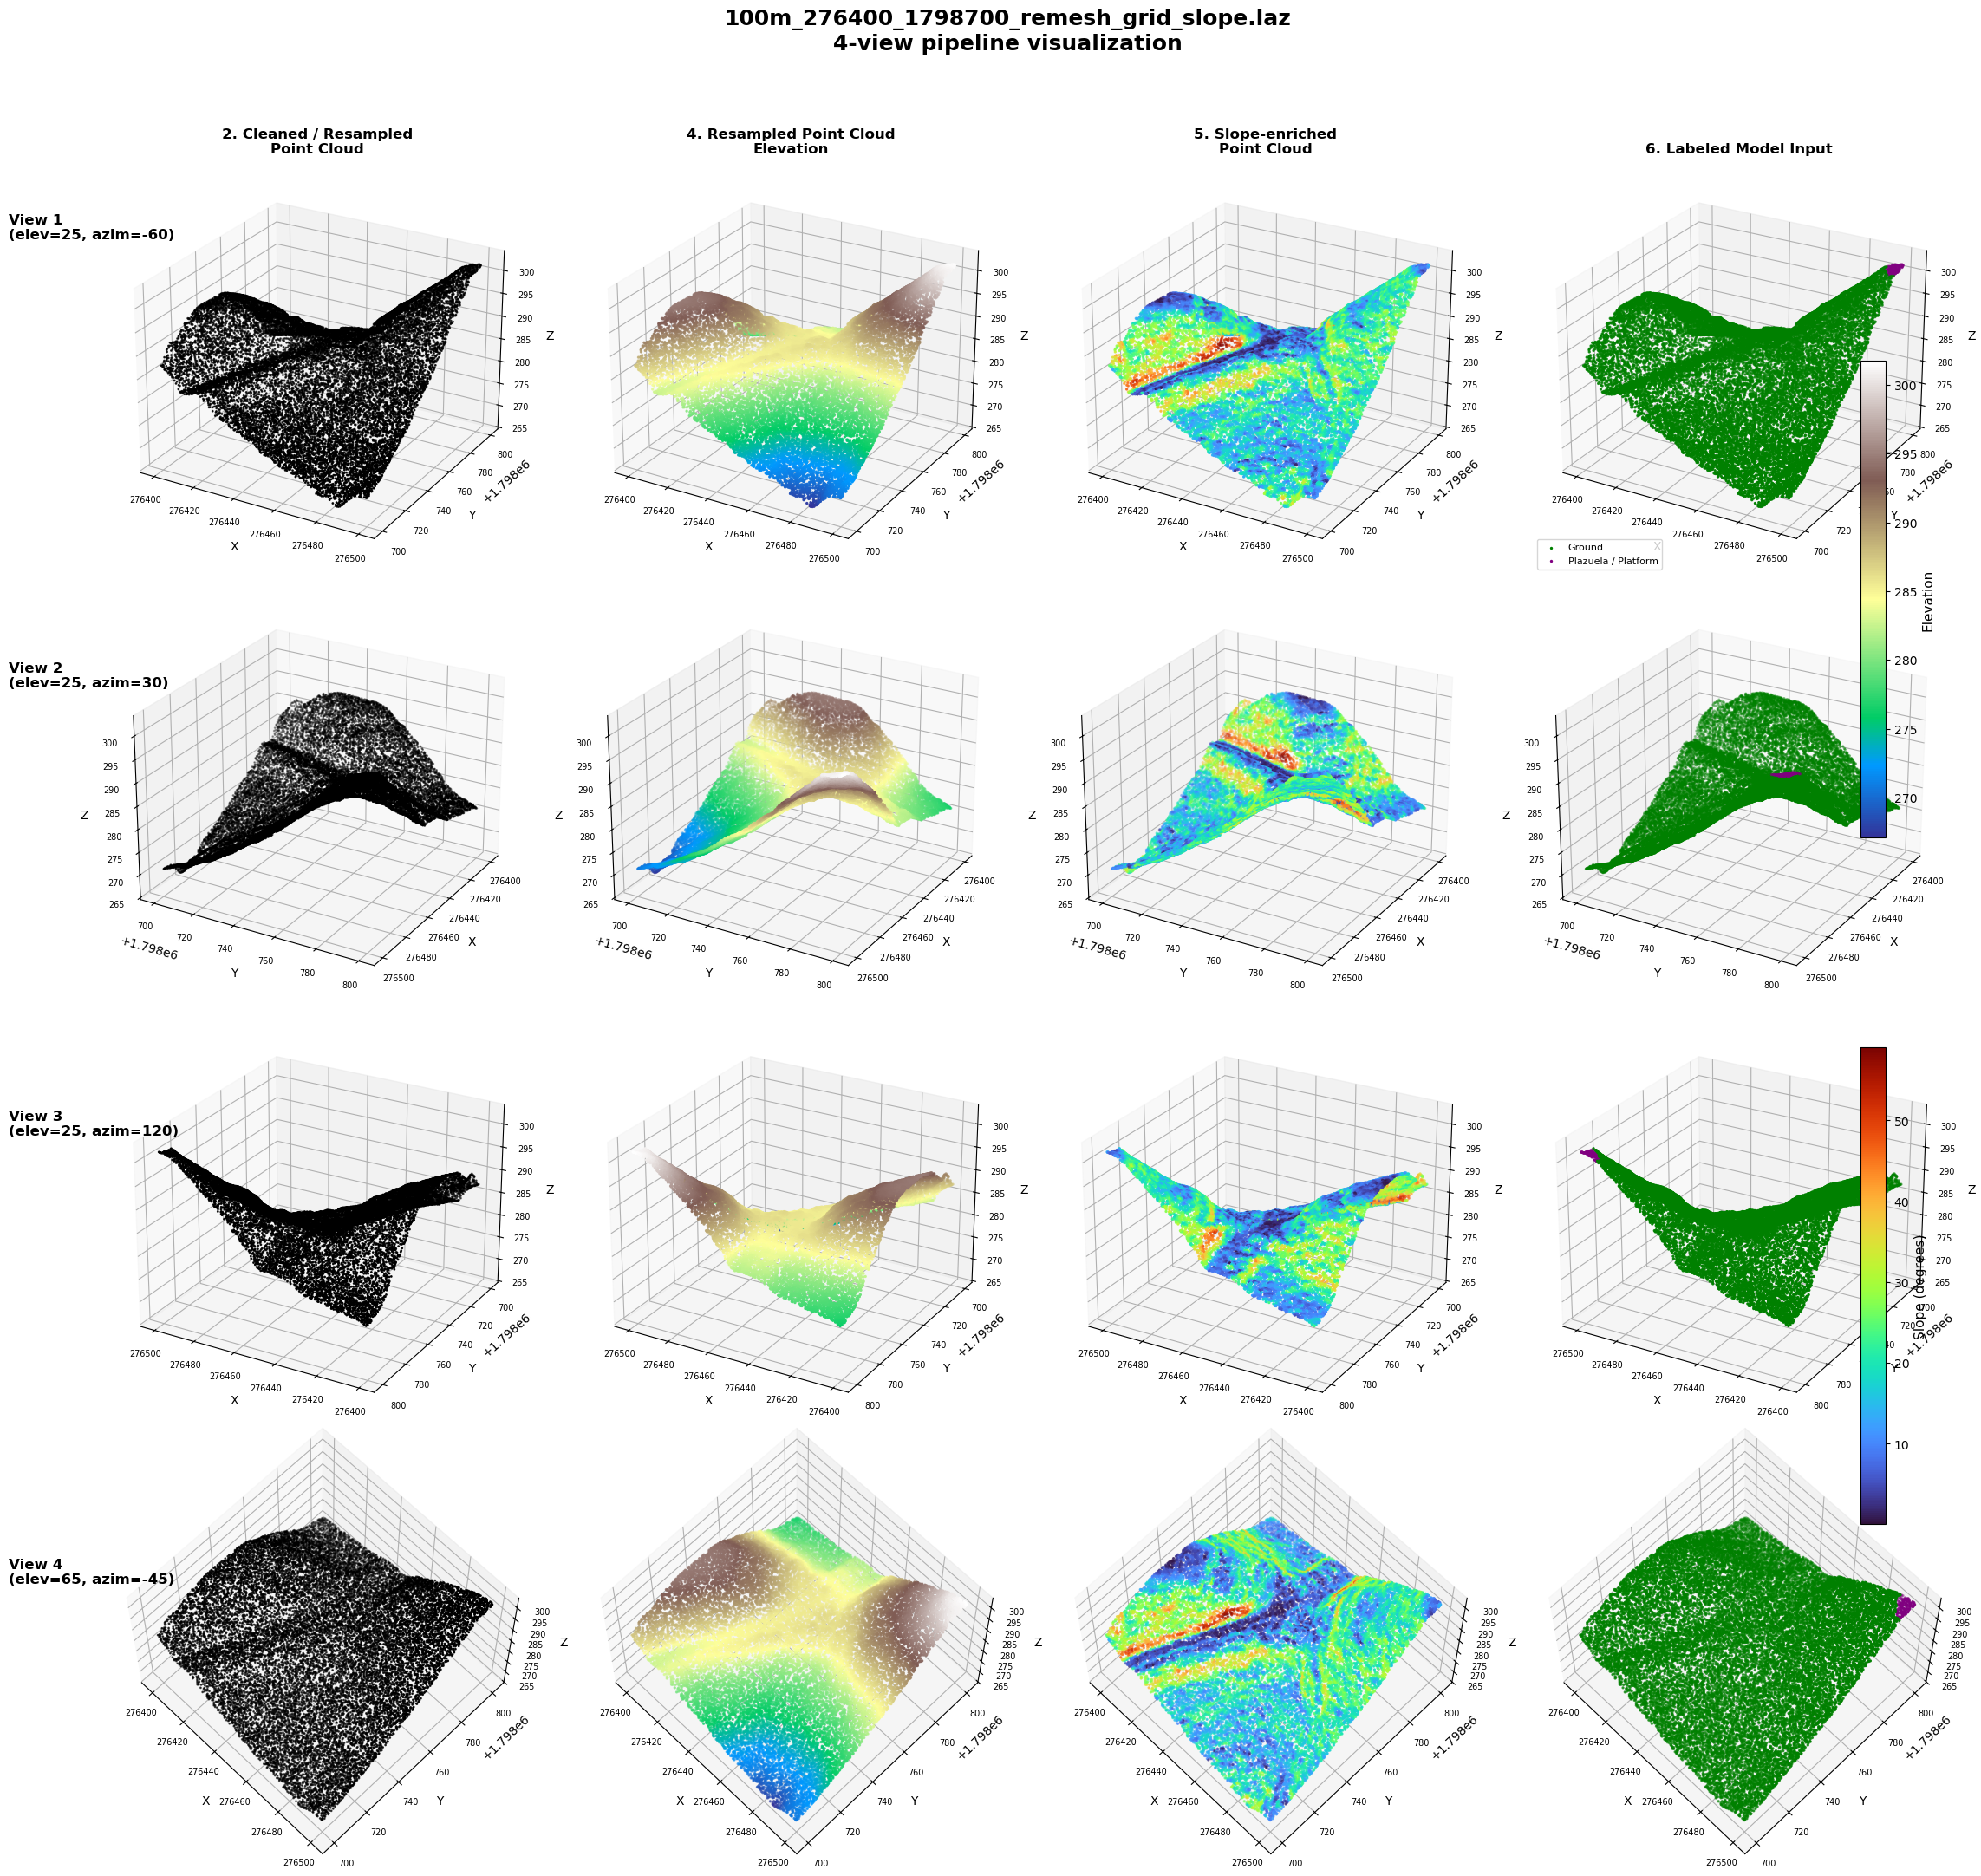

In [35]:
from pathlib import Path
import laspy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# SETTINGS
# ============================================================

DATA_DIR = Path(
    "/path/to/project_storage/2026_Data/"
    "training_data_filtered/"
)

GROUND_CLASS = 2
STRUCTURE_CLASS = 6
PLAZUELA_CLASS = 27

CLASS_COLORS = {
    GROUND_CLASS: "green",
    STRUCTURE_CLASS: "gray",
    PLAZUELA_CLASS: "purple",
}

CLASS_NAMES = {
    GROUND_CLASS: "Ground",
    STRUCTURE_CLASS: "Structure",
    PLAZUELA_CLASS: "Plazuela / Platform",
}


# ============================================================
# RANDOM TILE
# ============================================================

laz_files = sorted(
    DATA_DIR.glob("*.laz")
)

if not laz_files:
    raise FileNotFoundError(
        f"No LAZ files found in {DATA_DIR}"
    )

rng = np.random.default_rng()

random_file = rng.choice(
    laz_files
)

print("Selected tile:")
print(random_file.name)


# ============================================================
# READ LAZ
# ============================================================

las = laspy.read(
    random_file
)

xyz = np.column_stack([
    np.asarray(las.x),
    np.asarray(las.y),
    np.asarray(las.z),
]).astype(
    np.float32
)

labels = np.asarray(
    las.classification,
    dtype=np.int32
)

slope = np.asarray(
    las.slope,
    dtype=np.float32
)


# ============================================================
# OPTIONAL SUBSAMPLE FOR PLOTTING
# ============================================================

MAX_POINTS = 20000

if len(xyz) > MAX_POINTS:

    idx = rng.choice(
        len(xyz),
        MAX_POINTS,
        replace=False
    )

else:

    idx = np.arange(
        len(xyz)
    )

p_xyz = xyz[idx]
p_labels = labels[idx]
p_slope = slope[idx]


# ============================================================
# CREATE 4-STRIP PIPELINE FIGURE
# each row = same 4 panels from a different angle
# ============================================================

# 4 different viewing angles
views = [
    (25, -60),   # strip 1: front-left
    (25,  30),   # strip 2: front-right
    (25, 120),   # strip 3: back-right
    (65, -45),   # strip 4: top-oblique
]

view_names = [
    "View 1",
    "View 2",
    "View 3",
    "View 4",
]

col_titles = [
    "2. Cleaned / Resampled\nPoint Cloud",
    "4. Resampled Point Cloud\nElevation",
    "5. Slope-enriched\nPoint Cloud",
    "6. Labeled Model Input",
]

fig = plt.figure(figsize=(24, 22))

axes = []
for r in range(4):
    row_axes = []
    for c in range(4):
        ax = fig.add_subplot(
            4,
            4,
            r * 4 + c + 1,
            projection="3d"
        )
        row_axes.append(ax)
    axes.append(row_axes)

# keep handles for shared colorbars
sc2_for_cbar = None
sc3_for_cbar = None

for r, (elev, azim) in enumerate(views):

    # --------------------------------------------------------
    # PANEL 1: cleaned / final point geometry
    # --------------------------------------------------------
    ax1 = axes[r][0]

    ax1.scatter(
        p_xyz[:, 0],
        p_xyz[:, 1],
        p_xyz[:, 2],
        s=1,
        c="black"
    )

    if r == 0:
        ax1.set_title(
            col_titles[0],
            fontweight="bold",
            fontsize=12
        )

    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.set_zlabel("Z")
    ax1.view_init(elev=elev, azim=azim)
    ax1.tick_params(labelsize=7)

    # --------------------------------------------------------
    # PANEL 2: elevation
    # --------------------------------------------------------
    ax2 = axes[r][1]

    sc2 = ax2.scatter(
        p_xyz[:, 0],
        p_xyz[:, 1],
        p_xyz[:, 2],
        c=p_xyz[:, 2],
        s=2,
        cmap="terrain"
    )

    if sc2_for_cbar is None:
        sc2_for_cbar = sc2

    if r == 0:
        ax2.set_title(
            col_titles[1],
            fontweight="bold",
            fontsize=12
        )

    ax2.set_xlabel("X")
    ax2.set_ylabel("Y")
    ax2.set_zlabel("Z")
    ax2.view_init(elev=elev, azim=azim)
    ax2.tick_params(labelsize=7)

    # --------------------------------------------------------
    # PANEL 3: slope
    # --------------------------------------------------------
    ax3 = axes[r][2]

    sc3 = ax3.scatter(
        p_xyz[:, 0],
        p_xyz[:, 1],
        p_xyz[:, 2],
        c=p_slope,
        s=2,
        cmap="turbo"
    )

    if sc3_for_cbar is None:
        sc3_for_cbar = sc3

    if r == 0:
        ax3.set_title(
            col_titles[2],
            fontweight="bold",
            fontsize=12
        )

    ax3.set_xlabel("X")
    ax3.set_ylabel("Y")
    ax3.set_zlabel("Z")
    ax3.view_init(elev=elev, azim=azim)
    ax3.tick_params(labelsize=7)

    # --------------------------------------------------------
    # PANEL 4: labels
    # --------------------------------------------------------
    ax4 = axes[r][3]

    for cls in [
        GROUND_CLASS,
        STRUCTURE_CLASS,
        PLAZUELA_CLASS,
    ]:

        mask = (
            p_labels == cls
        )

        if np.any(mask):

            ax4.scatter(
                p_xyz[mask, 0],
                p_xyz[mask, 1],
                p_xyz[mask, 2],
                s=2,
                c=CLASS_COLORS[cls],
                label=CLASS_NAMES[cls]
            )

    if r == 0:
        ax4.set_title(
            col_titles[3],
            fontweight="bold",
            fontsize=12
        )

    ax4.set_xlabel("X")
    ax4.set_ylabel("Y")
    ax4.set_zlabel("Z")
    ax4.view_init(elev=elev, azim=azim)
    ax4.tick_params(labelsize=7)

    if r == 0:
        ax4.legend(
            loc="lower left",
            fontsize=8
        )

    # --------------------------------------------------------
    # row label on left side
    # --------------------------------------------------------
    fig.text(
        0.02,
        0.88 - r * 0.235,
        f"{view_names[r]}\n(elev={elev}, azim={azim})",
        fontsize=12,
        fontweight="bold",
        va="center",
        ha="left"
    )

# ============================================================
# SHARED COLORBARS OUTSIDE THE FIGURE GRID
# ============================================================

# Leave room on the right side of the figure
plt.subplots_adjust(
    right=0.90,
    wspace=0.12,
    hspace=0.18
)

# Elevation colorbar
cax1 = fig.add_axes([
    0.91,   # left
    0.56,   # bottom
    0.012,  # width
    0.25    # height
])

cbar1 = fig.colorbar(
    sc2_for_cbar,
    cax=cax1
)

cbar1.set_label(
    "Elevation",
    fontsize=11
)


# Slope colorbar
cax2 = fig.add_axes([
    0.91,
    0.20,
    0.012,
    0.25
])

cbar2 = fig.colorbar(
    sc3_for_cbar,
    cax=cax2
)

cbar2.set_label(
    "Slope (degrees)",
    fontsize=11
)

# ============================================================
# TITLE
# ============================================================

fig.suptitle(
    f"{random_file.name}\n4-view pipeline visualization",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0.04, 0.02, 0.98, 0.97])

# ============================================================
# SAVE HIGH-RES FIGURE
# ============================================================

save_dir = Path(
    "/path/to/authorized/training_laz/"
)

save_path = save_dir / "visualization_4views.png"

fig.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

print("Saved figure to:")
print(save_path)

plt.show()

Tiles containing Ground + Structure + Plazuela: 274
Selected classified tile: tile_redacted_0005.laz
Selected original tile:
tile_redacted_0006.laz
Tile origin: 277100 1796200
Original center points: 12,718
Points used for reconstruction: 20,001
Mesh vertices: 21,814
Grid sampled points: 99,125
Structure shapefile: /path/to/authorized/shapefiles/UXB_Structures_polgyons_8April2024.shp
Plazuela shapefile: /path/to/authorized/shapefiles/AllPlazuelasSurveyed_8April2024.shp
Final center points: 70,225

Saved:
/path/to/authorized/training_laz/processing_pipeline_4views.png


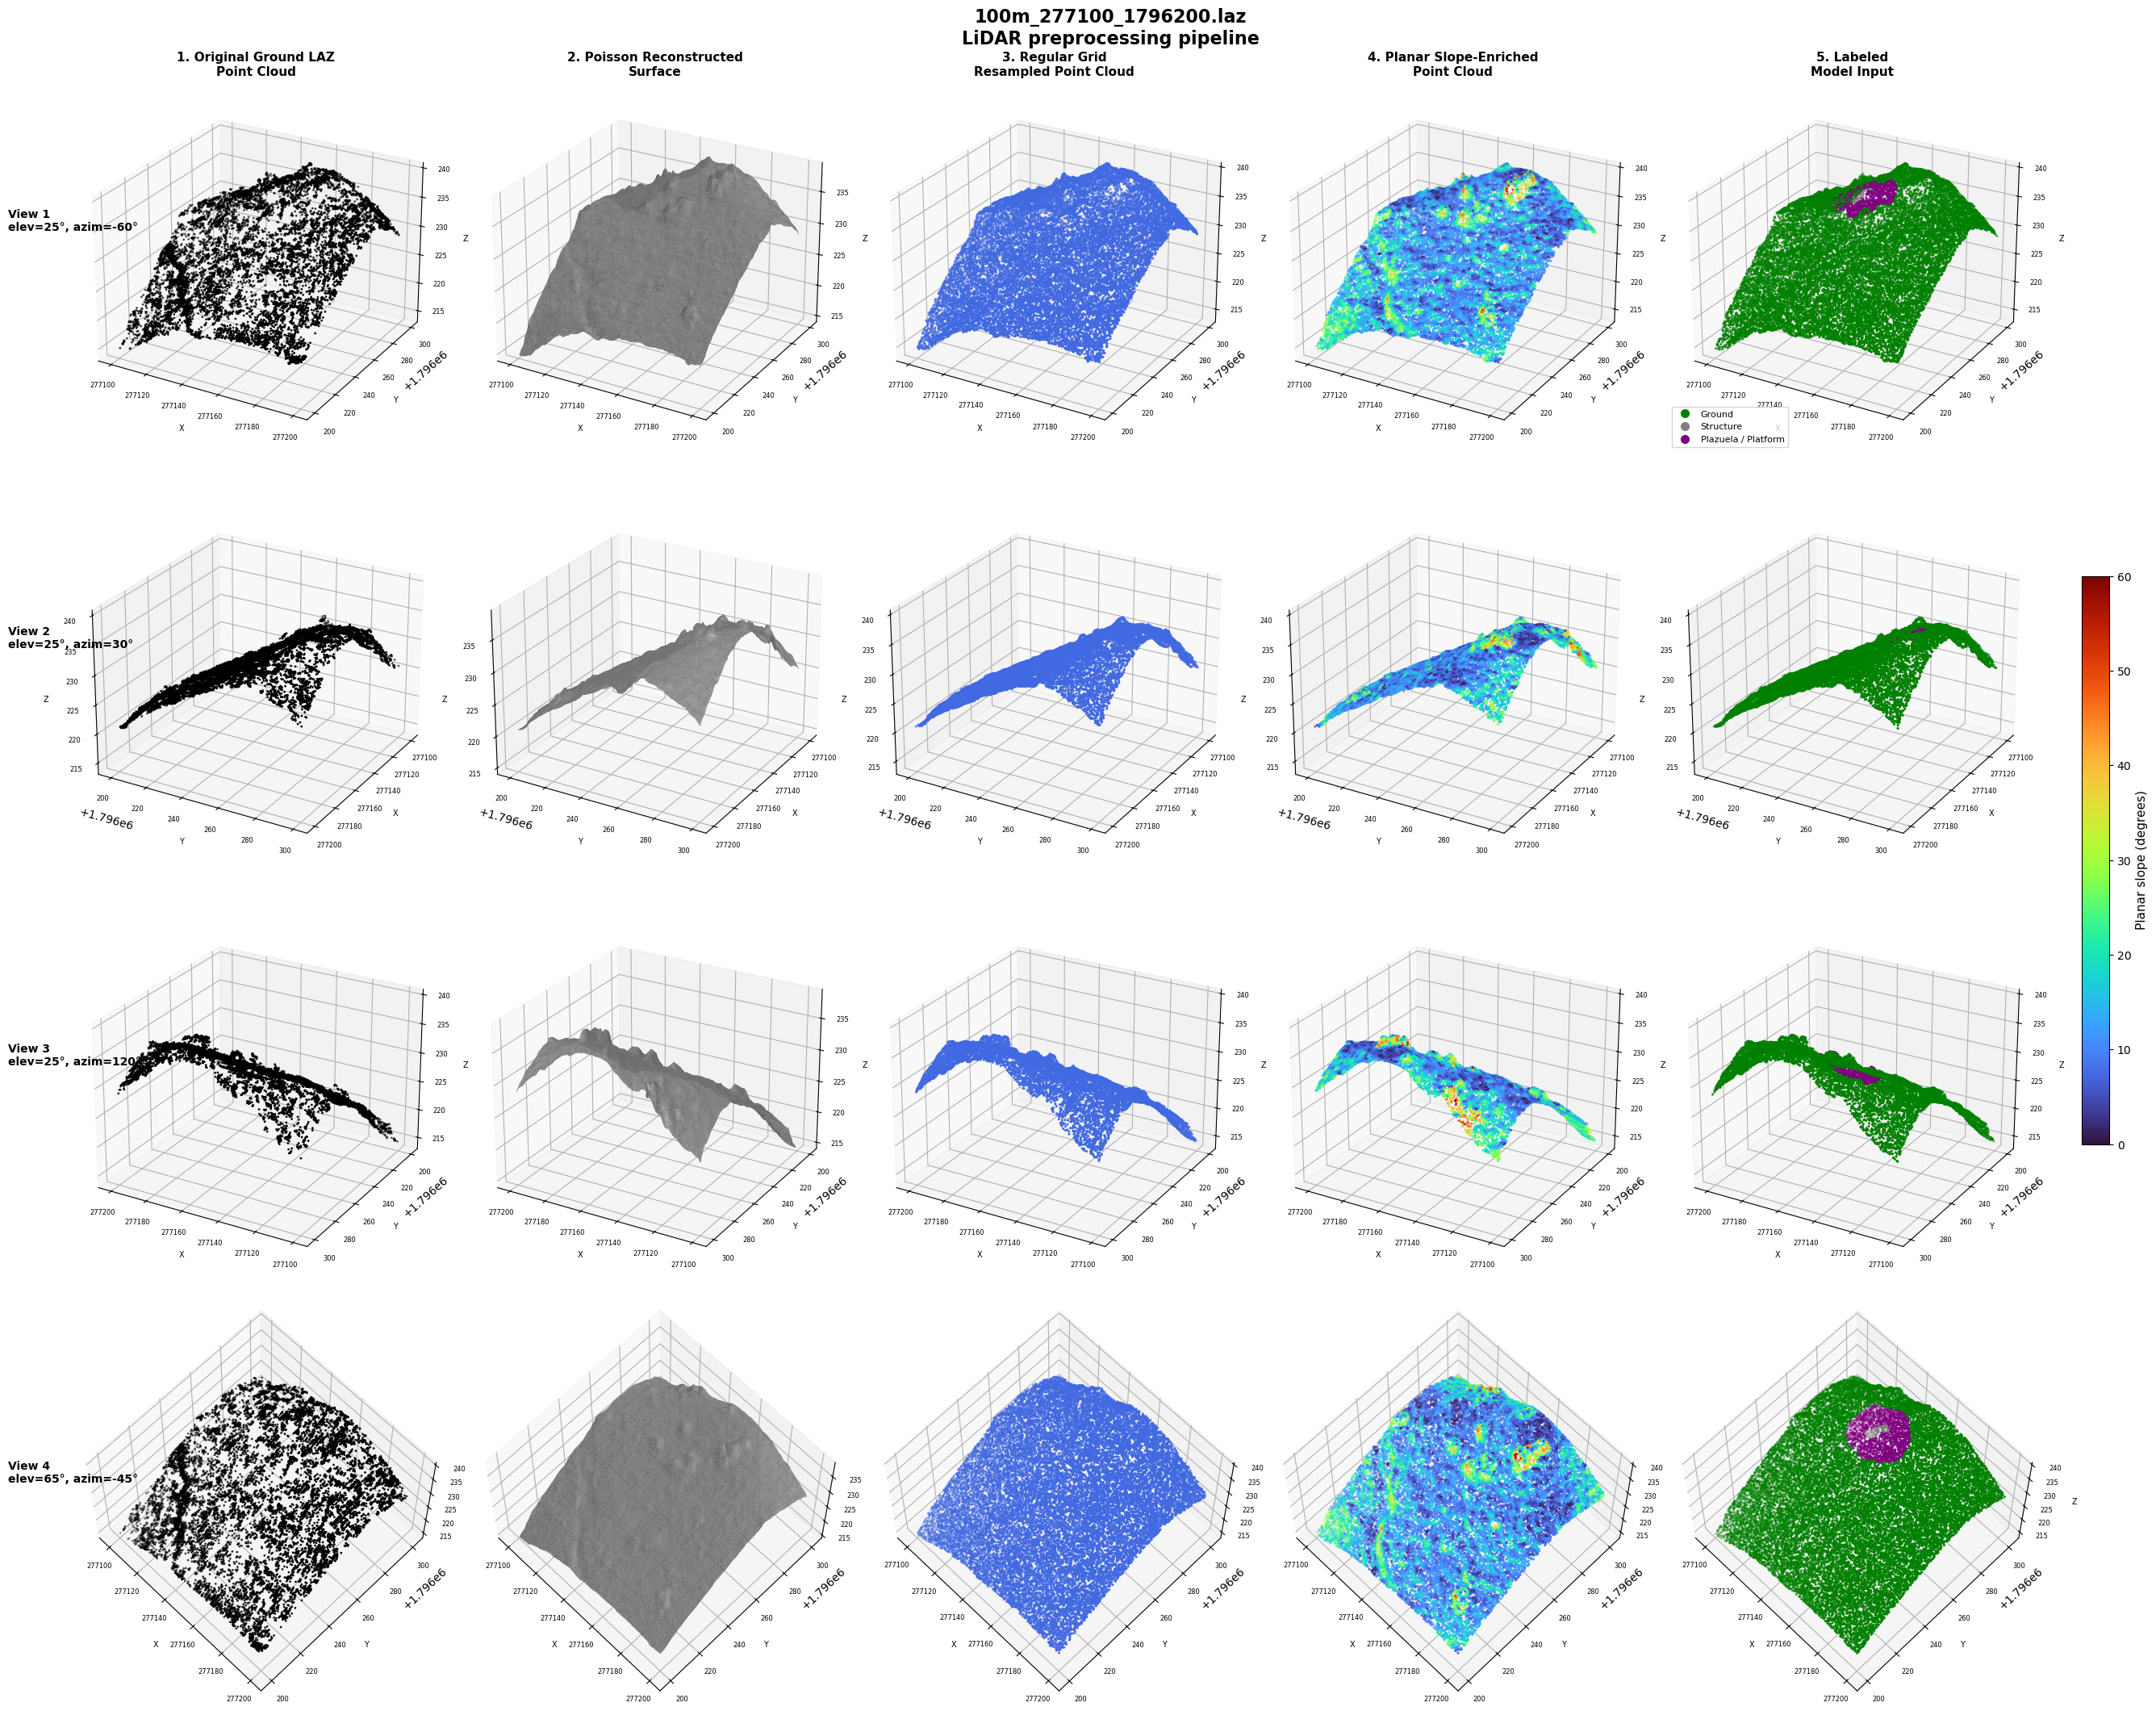

800

In [39]:
from pathlib import Path
import gc
import laspy
import numpy as np
import matplotlib.pyplot as plt
import open3d as o3d
from matplotlib.lines import Line2D


# ============================================================
# INPUT
# ============================================================

LAZ_INPUT_DIR = Path(
    "/path/to/project_storage/2026_Data/"
    "uxb_grnd_100m_tile_laz/"
)

GROUND_CLASS = 2
STRUCTURE_CLASS = 6
PLAZUELA_CLASS = 27

CLASS_COLORS = {
    GROUND_CLASS: "green",
    STRUCTURE_CLASS: "gray",
    PLAZUELA_CLASS: "purple",
}

CLASS_NAMES = {
    GROUND_CLASS: "Ground",
    STRUCTURE_CLASS: "Structure",
    PLAZUELA_CLASS: "Plazuela / Platform",
}

MAX_PLOT_POINTS = 20000


# ============================================================
# RANDOM TILE THAT CONTAINS ALL 3 CLASSES
# ============================================================

FILTERED_DIR = Path(
    "/path/to/project_storage/2026_Data/"
    "training_data_filtered/"
)

filtered_files = sorted(
    FILTERED_DIR.glob("*.laz")
)

if not filtered_files:
    raise FileNotFoundError(
        f"No filtered LAZ files found in {FILTERED_DIR}"
    )

rng = np.random.default_rng()

candidate_files = []

for path in filtered_files:

    las_check = laspy.read(path)

    cls = np.asarray(
        las_check.classification
    )

    has_ground = np.any(
        cls == GROUND_CLASS
    )

    has_structure = np.any(
        cls == STRUCTURE_CLASS
    )

    has_plazuela = np.any(
        cls == PLAZUELA_CLASS
    )

    if (
        has_ground
        and
        has_structure
        and
        has_plazuela
    ):
        candidate_files.append(
            path
        )


print(
    "Tiles containing Ground + Structure + Plazuela:",
    len(candidate_files)
)

if not candidate_files:
    raise RuntimeError(
        "No tiles containing all 3 classes were found."
    )


# Randomly select one final classified tile
selected_filtered = rng.choice(
    candidate_files
)

print(
    "Selected classified tile:",
    selected_filtered.name
)


# ============================================================
# FIND MATCHING ORIGINAL LAZ
# ============================================================

# Example final filename:
# tile_redacted_0007.laz
#
# Original:
# tile_redacted_0008.laz

parts = selected_filtered.stem.split("_")

tile_x = int(
    parts[1]
)

tile_y = int(
    parts[2]
)

random_path = (
    LAZ_INPUT_DIR
    /
    f"100m_{tile_x}_{tile_y}.laz"
)

if not random_path.exists():

    raise FileNotFoundError(
        f"Matching original tile not found: {random_path}"
    )

x = tile_x
y = tile_y

print("=" * 70)
print("Selected original tile:")

print(random_path.name)

print("Tile origin:",x,y)

print("=" * 70)

# ============================================================
# BUILD TILE LOOKUP DIRECTLY FROM ORIGINAL LAZ FOLDER
# ============================================================

tile_lookup_vis = {}

for p in original_files:

    tx, ty = tile_origin(p)

    tile_lookup_vis[
        (tx, ty)
    ] = p


# ============================================================
# STEP 1
# ORIGINAL CENTER TILE
# ============================================================

original_xyz, crs_original = read_laz_xyz(
    random_path
)

print(
    "Original center points:",
    f"{len(original_xyz):,}"
)


# ============================================================
# STEP 2
# CENTER + NEIGHBOR BUFFER
# ============================================================

neighbor_paths = get_neighbors(
    x,
    y,
    tile_lookup_vis
)

merged_xyz, _ = load_neighbors(
    neighbor_paths,
    x,
    y
)

print(
    "Points used for reconstruction:",
    f"{len(merged_xyz):,}"
)


# ============================================================
# STEP 3
# POISSON RECONSTRUCTION
# same method used by pipeline
# ============================================================

pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(
    merged_xyz
)

pcd.remove_duplicated_points()
pcd.remove_non_finite_points()


# Optional preprocessing if this is already
# part of your actual remesh function
if "POISSON_INPUT_VOXEL" in globals():

    if POISSON_INPUT_VOXEL is not None:

        if POISSON_INPUT_VOXEL > 0:

            pcd = pcd.voxel_down_sample(
                POISSON_INPUT_VOXEL
            )


pcd.estimate_normals(
    search_param=(
        o3d.geometry.KDTreeSearchParamHybrid(
            radius=NORMAL_RADIUS,
            max_nn=20
        )
    )
)

# Keep this if your actual processing pipeline uses it
try:

    pcd.orient_normals_consistent_tangent_plane(
        30
    )

except Exception:

    pass


mesh, _ = (
    o3d.geometry.TriangleMesh
    .create_from_point_cloud_poisson(
        pcd,
        depth=POISSON_DEPTH,
        scale=1.0,
        linear_fit=True
    )
)

mesh.remove_degenerate_triangles()
mesh.remove_duplicated_triangles()
mesh.remove_duplicated_vertices()
mesh.remove_non_manifold_edges()


# Crop reconstructed mesh to buffered processing extent
mins = merged_xyz.min(axis=0)
maxs = merged_xyz.max(axis=0)

bbox = o3d.geometry.AxisAlignedBoundingBox(

    min_bound=(
        mins[0],
        mins[1],
        mins[2] - 5
    ),

    max_bound=(
        maxs[0],
        maxs[1],
        maxs[2] + 5
    )
)

mesh = mesh.crop(
    bbox
)

print(
    "Mesh vertices:",
    f"{len(mesh.vertices):,}"
)


# ============================================================
# STEP 4
# REGULAR GRID RESAMPLING
# use your already-defined sample_mesh_grid()
# ============================================================

sampled_xyz = sample_mesh_grid(

    mesh,

    xmin=x - NEIGHBOR_BUFFER,
    xmax=x + TILE_SIZE + NEIGHBOR_BUFFER,

    ymin=y - NEIGHBOR_BUFFER,
    ymax=y + TILE_SIZE + NEIGHBOR_BUFFER,

    spacing=GRID_SPACING
)

print(
    "Grid sampled points:",
    f"{len(sampled_xyz):,}"
)

# ============================================================
# LOAD STRUCTURE + PLAZUELA SHAPEFILES
# ============================================================

SHP_DIR = Path(
    "/path/to/project_storage/2026_Data/"
    "UXB_shapefiles_8April2024/"
)

structure_shp = list(
    SHP_DIR.glob("*Structure*.shp")
)[0]

plazuela_shp = list(
    SHP_DIR.glob("*Plazuela*.shp")
)[0]

print("Structure shapefile:", structure_shp)
print("Plazuela shapefile:", plazuela_shp)

structures, plazuelas = load_classification_shapes(
    crs_original
)

# ============================================================
# STEP 5
# CLASSIFICATION
# ============================================================

labels = classify_points(

    sampled_xyz,

    structures,

    plazuelas,

    crs_original
)


# ============================================================
# STEP 6
# DEM FROM ALL RESAMPLED POINTS
#
# Important:
# use ALL sampled points for the elevation surface,
# not only class-2 ground.
# ============================================================

dem, xmin_dem, ymax_dem = create_dem(
    sampled_xyz
)


# ============================================================
# STEP 7
# PLANAR SLOPE
# ============================================================

slope_raster = calculate_slope(
    dem
)

slopes = sample_slope(

    sampled_xyz,

    slope_raster,

    xmin_dem,

    ymax_dem
)


# ============================================================
# STEP 8
# CROP FINAL CENTER 100 m TILE
# ============================================================

center_mask = (

    (sampled_xyz[:, 0] >= x)
    &
    (sampled_xyz[:, 0] < x + TILE_SIZE)
    &
    (sampled_xyz[:, 1] >= y)
    &
    (sampled_xyz[:, 1] < y + TILE_SIZE)

)

center_xyz = sampled_xyz[
    center_mask
].copy()

center_labels = labels[
    center_mask
]

center_slopes = slopes[
    center_mask
]


print(
    "Final center points:",
    f"{len(center_xyz):,}"
)


# ============================================================
# CROP MESH TO CENTER TILE FOR DISPLAY ONLY
# ============================================================

zmin = center_xyz[:, 2].min()
zmax = center_xyz[:, 2].max()

center_bbox = o3d.geometry.AxisAlignedBoundingBox(

    min_bound=(
        x,
        y,
        zmin - 5
    ),

    max_bound=(
        x + TILE_SIZE,
        y + TILE_SIZE,
        zmax + 5
    )

)

mesh_center = mesh.crop(
    center_bbox
)

mesh_vertices = np.asarray(
    mesh_center.vertices
)

mesh_triangles = np.asarray(
    mesh_center.triangles
)


# ============================================================
# ORIGINAL CENTER ONLY FOR VIS
# ============================================================

orig_mask = (

    (original_xyz[:, 0] >= x)
    &
    (original_xyz[:, 0] < x + TILE_SIZE)
    &
    (original_xyz[:, 1] >= y)
    &
    (original_xyz[:, 1] < y + TILE_SIZE)

)

original_center_xyz = original_xyz[
    orig_mask
]


# ============================================================
# SUBSAMPLING FUNCTION
# ============================================================

def subsample_with_attributes(
    xyz,
    *attributes,
    max_points=MAX_PLOT_POINTS
):

    if len(xyz) <= max_points:

        return (
            xyz,
            *attributes
        )

    idx = rng.choice(

        len(xyz),

        max_points,

        replace=False
    )

    outputs = [
        xyz[idx]
    ]

    for attr in attributes:

        outputs.append(
            attr[idx]
        )

    return tuple(
        outputs
    )


original_plot, = subsample_with_attributes(
    original_center_xyz
)

resampled_plot, = subsample_with_attributes(
    center_xyz
)

slope_xyz_plot, slope_plot = (
    subsample_with_attributes(
        center_xyz,
        center_slopes
    )
)

label_xyz_plot, label_plot = (
    subsample_with_attributes(
        center_xyz,
        center_labels
    )
)


# ============================================================
# 4 VIEW ANGLES
# ============================================================

views = [
    (25, -60),
    (25, 30),
    (25, 120),
    (65, -45),
]

view_names = [
    "View 1",
    "View 2",
    "View 3",
    "View 4",
]


# ============================================================
# FIGURE
#
# 5 columns:
#
# Original  Mesh  Resampled  Slope  Labels
# ============================================================

fig = plt.figure(
    figsize=(28, 22)
)

axes = []

for r in range(4):

    row = []

    for c in range(5):

        ax = fig.add_subplot(

            4,
            5,

            r * 5 + c + 1,

            projection="3d"
        )

        row.append(
            ax
        )

    axes.append(
        row
    )


column_titles = [

    "1. Original Ground LAZ\nPoint Cloud",

    "2. Poisson Reconstructed\nSurface",

    "3. Regular Grid\nResampled Point Cloud",

    "4. Planar Slope-Enriched\nPoint Cloud",

    "5. Labeled\nModel Input",

]


# Common slope scale
slope_vmin = 0

slope_vmax = max(
    60,
    float(
        np.nanpercentile(
            center_slopes,
            99
        )
    )
)

slope_scatter = None


# ============================================================
# DRAW ROWS
# ============================================================

for r, (
    elev,
    azim
) in enumerate(
    views
):

    # ========================================================
    # PANEL 1
    # ORIGINAL LAZ
    # ========================================================

    ax = axes[r][0]

    ax.scatter(

        original_plot[:, 0],

        original_plot[:, 1],

        original_plot[:, 2],

        s=1,

        c="black"
    )


    # ========================================================
    # PANEL 2
    # RECONSTRUCTED SURFACE
    # ========================================================

    ax = axes[r][1]

    if (
        len(mesh_vertices) > 0
        and
        len(mesh_triangles) > 0
    ):

        ax.plot_trisurf(

            mesh_vertices[:, 0],

            mesh_vertices[:, 1],

            mesh_vertices[:, 2],

            triangles=mesh_triangles,

            color="lightgray",

            edgecolor="gray",

            linewidth=0.1,

            alpha=0.95
        )


    # ========================================================
    # PANEL 3
    # RESAMPLED
    # ========================================================

    ax = axes[r][2]

    ax.scatter(

        resampled_plot[:, 0],

        resampled_plot[:, 1],

        resampled_plot[:, 2],

        s=1.5,

        c="royalblue"
    )


    # ========================================================
    # PANEL 4
    # SLOPE
    # ========================================================

    ax = axes[r][3]

    slope_scatter = ax.scatter(

        slope_xyz_plot[:, 0],

        slope_xyz_plot[:, 1],

        slope_xyz_plot[:, 2],

        c=slope_plot,

        s=1.5,

        cmap="turbo",

        vmin=slope_vmin,

        vmax=slope_vmax
    )


    # ========================================================
    # PANEL 5
    # LABELS
    # ========================================================

    ax = axes[r][4]

    for cls in [

        GROUND_CLASS,

        STRUCTURE_CLASS,

        PLAZUELA_CLASS

    ]:

        m = (
            label_plot == cls
        )

        if not np.any(m):

            continue

        ax.scatter(

            label_xyz_plot[m, 0],

            label_xyz_plot[m, 1],

            label_xyz_plot[m, 2],

            s=1.5,

            c=CLASS_COLORS[cls],

            label=CLASS_NAMES[cls]
        )


    # ========================================================
    # COMMON AXIS SETTINGS
    # ========================================================

    for c in range(5):

        ax = axes[r][c]

        ax.view_init(

            elev=elev,

            azim=azim
        )

        ax.set_xlabel(
            "X",
            fontsize=7
        )

        ax.set_ylabel(
            "Y",
            fontsize=7
        )

        ax.set_zlabel(
            "Z",
            fontsize=7
        )

        ax.tick_params(
            labelsize=6
        )


        if r == 0:

            ax.set_title(

                column_titles[c],

                fontsize=11,

                fontweight="bold"
            )


    # Row labels
    fig.text(

        0.012,

        0.86 - r * 0.235,

        (
            f"{view_names[r]}\n"
            f"elev={elev}°, "
            f"azim={azim}°"
        ),

        fontsize=10,

        fontweight="bold",

        va="center"
    )


# ============================================================
# LABEL LEGEND
# ============================================================

legend_handles = [

    Line2D(

        [0],
        [0],

        marker="o",

        linestyle="",

        markerfacecolor=(
            CLASS_COLORS[
                GROUND_CLASS
            ]
        ),

        markeredgecolor="none",

        markersize=8,

        label="Ground"
    ),

    Line2D(

        [0],
        [0],

        marker="o",

        linestyle="",

        markerfacecolor=(
            CLASS_COLORS[
                STRUCTURE_CLASS
            ]
        ),

        markeredgecolor="none",

        markersize=8,

        label="Structure"
    ),

    Line2D(

        [0],
        [0],

        marker="o",

        linestyle="",

        markerfacecolor=(
            CLASS_COLORS[
                PLAZUELA_CLASS
            ]
        ),

        markeredgecolor="none",

        markersize=8,

        label="Plazuela / Platform"
    ),

]

axes[0][4].legend(

    handles=legend_handles,

    loc="lower left",

    fontsize=8
)


# ============================================================
# LEAVE SPACE FOR COLORBAR
# ============================================================

plt.subplots_adjust(

    left=0.04,

    right=0.91,

    top=0.94,

    bottom=0.03,

    wspace=0.08,

    hspace=0.10
)


# ============================================================
# SLOPE COLORBAR OUTSIDE ALL PANELS
# ============================================================

cax = fig.add_axes([

    0.93,

    0.34,

    0.012,

    0.32

])

cbar = fig.colorbar(

    slope_scatter,

    cax=cax
)

cbar.set_label(

    "Planar slope (degrees)",

    fontsize=11
)


# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(

    (
        f"{random_path.name}\n"
        "LiDAR preprocessing pipeline"
    ),

    fontsize=16,

    fontweight="bold"
)


# ============================================================
# SAVE
# ============================================================

save_path = Path(
    "/path/to/project_storage/2026_Data/"
    "training_data_filtered/"
    "processing_pipeline_4views.png"
)

fig.savefig(

    save_path,

    dpi=600,

    bbox_inches="tight",

    facecolor="white"
)

print(
    "\nSaved:"
)

print(
    save_path
)

plt.show()


# ============================================================
# CLEANUP
# ============================================================

del pcd
del mesh
del mesh_center

gc.collect()